## Anomaly & Uncertainty Map Rendering Module


           RENDERING PIPELINE VISUALIZATION ANOMALY ENGINE            

Displaying 4D Time-Lapse Maps for Date: 20250724
---------------------------------------------------------------------------


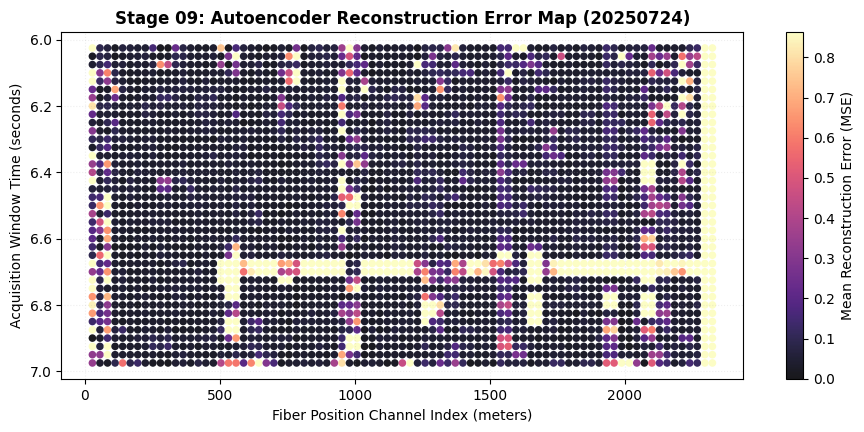

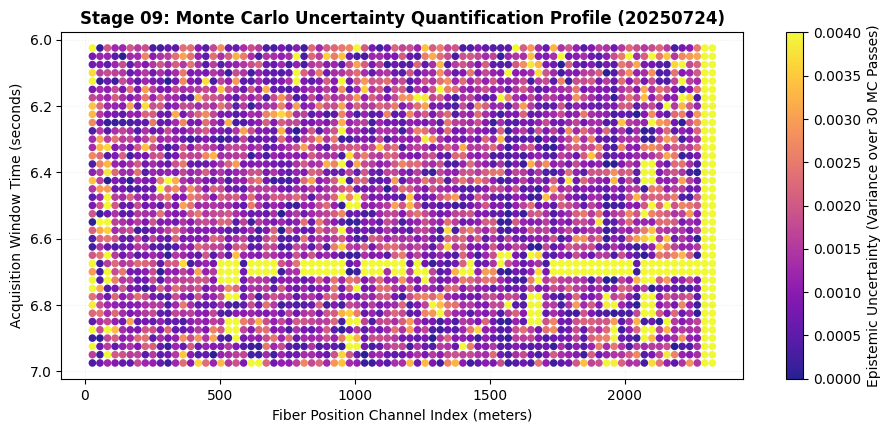

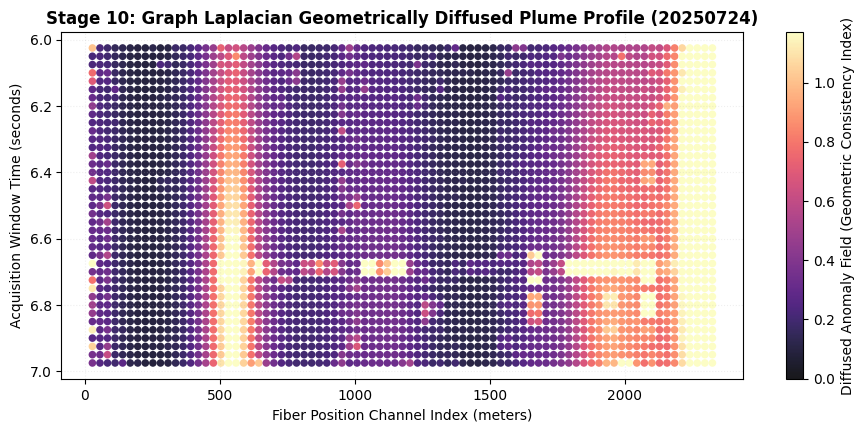


Displaying 4D Time-Lapse Maps for Date: 20250726
---------------------------------------------------------------------------


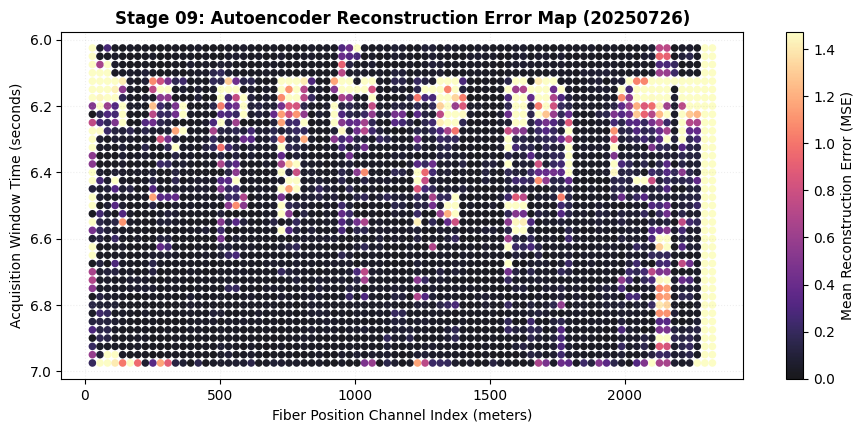

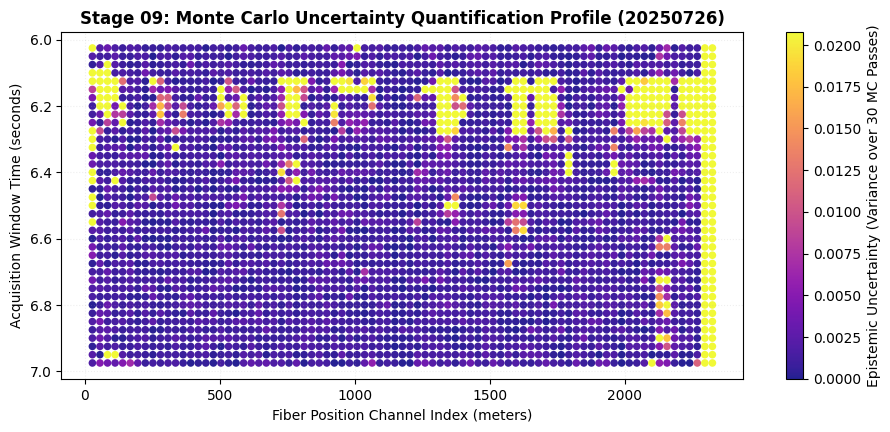

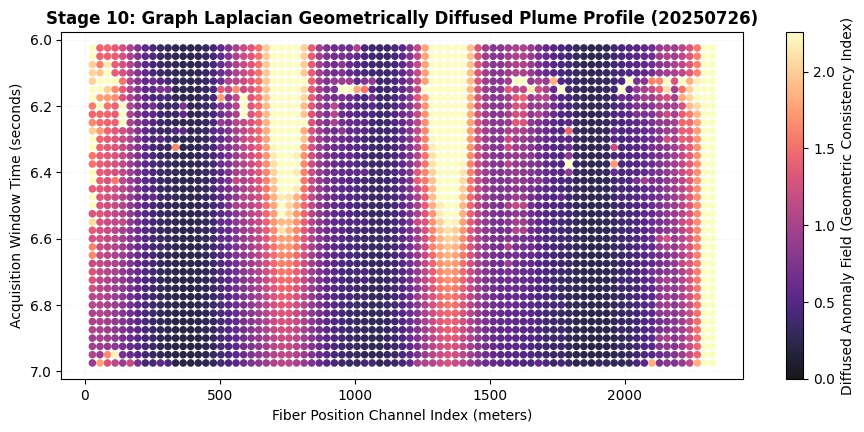


Displaying 4D Time-Lapse Maps for Date: 20250728
---------------------------------------------------------------------------


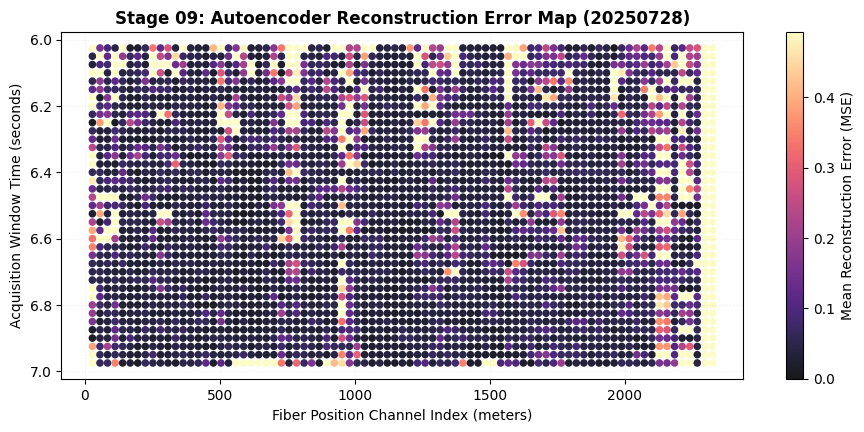

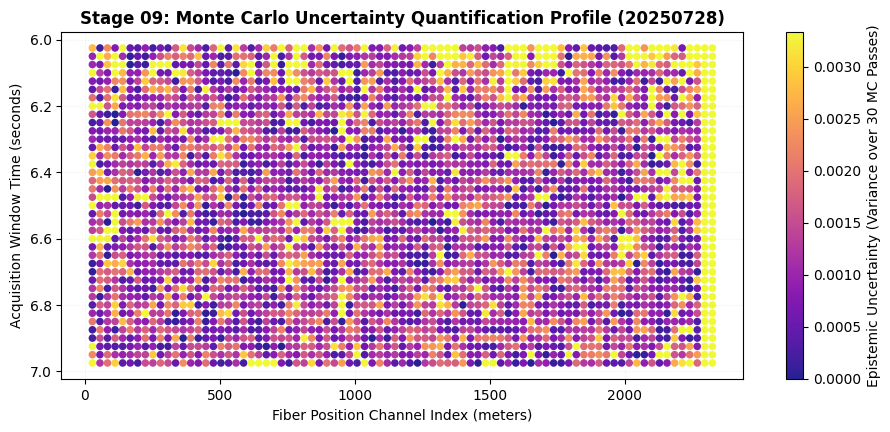

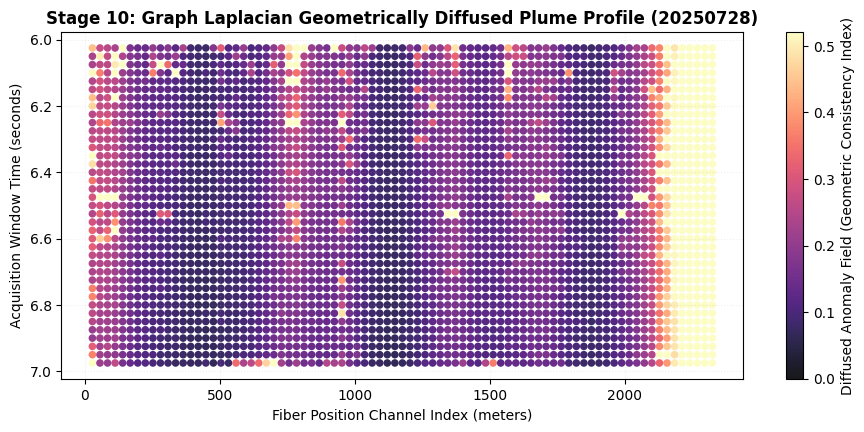


[SUCCESS] All maps displayed successfully and cached to results/figures/


In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

def plot_saved_pipeline_anomalies(metadata_path, base_path):
    """
    Loads completed pipeline tensors from disk and displays the 
    Unsupervised Anomaly, Uncertainty, and Graph Laplacian Diffused maps.
    """
    with open(metadata_path, 'r') as f:
        meta = json.load(f)
        
    dt = meta['dt_seconds']
    base_dir = Path(base_path)
    features_dir = base_dir / "features"
    figures_dir = base_dir / "figures"
    
    dates = ['20250724', '20250726', '20250728']
    
    print("=" * 75)
    print("           RENDERING PIPELINE VISUALIZATION ANOMALY ENGINE            ")
    print("=" * 75)
    
    for date in dates:
        coords_path = features_dir / f"dasgas_{date}_coords.npy"
        mse_path = features_dir / f"dasgas_{date}_mse.npy"
        unc_path = features_dir / f"dasgas_{date}_uncertainty.npy"
        diff_path = features_dir / f"dasgas_{date}_diffused.npy"
        
        # Verify file existence on disk
        if not all(p.exists() for p in [coords_path, mse_path, unc_path, diff_path]):
            print(f"  ✗ Skipping: Missing evaluated matrix blocks for date {date}")
            continue
            
        print(f"\nDisplaying 4D Time-Lapse Maps for Date: {date}")
        print("-" * 75)
        
        coords = np.load(coords_path)
        mse = np.load(mse_path)
        uncertainty = np.load(unc_path)
        diffused = np.load(diff_path)
        
        # Calculate time axis in true recording seconds
        time_axis_seconds = coords[:, 0] * dt + 6.0
        channel_index = coords[:, 1]
        
        # ----------------------------------------------------------------------
        # MAP 1: UNSUPERVISED AUTOENCODER RECONSTRUCTION ERROR (MEAN MSE)
        # ----------------------------------------------------------------------
        plt.figure(figsize=(11, 4.5))
        vmax_mse = np.percentile(mse, 92)
        sc1 = plt.scatter(channel_index, time_axis_seconds, c=mse, cmap="magma", 
                           s=30, alpha=0.9, edgecolor='none', vmin=0, vmax=vmax_mse)
        plt.title(f"Stage 09: Autoencoder Reconstruction Error Map ({date})", fontsize=12, fontweight='bold')
        plt.xlabel("Fiber Position Channel Index (meters)", fontsize=10)
        plt.ylabel("Acquisition Window Time (seconds)", fontsize=10)
        plt.colorbar(sc1, label="Mean Reconstruction Error (MSE)")
        plt.gca().invert_yaxis()
        plt.grid(alpha=0.2, linestyle=':')
        
        # Auto-save plot to figures folder matching project constraints
        plt.savefig(figures_dir / f"results_stage09_anomaly_map_{date}.png", bbox_inches='tight', dpi=150)
        plt.show()
        
        # ----------------------------------------------------------------------
        # MAP 2: MODEL EPISTEMIC UNCERTAINTY PROFILE (UQ)
        # ----------------------------------------------------------------------
        plt.figure(figsize=(11, 4.5))
        vmax_unc = np.percentile(uncertainty, 92)
        sc2 = plt.scatter(channel_index, time_axis_seconds, c=uncertainty, cmap="plasma", 
                           s=30, alpha=0.9, edgecolor='none', vmin=0, vmax=vmax_unc)
        plt.title(f"Stage 09: Monte Carlo Uncertainty Quantification Profile ({date})", fontsize=12, fontweight='bold')
        plt.xlabel("Fiber Position Channel Index (meters)", fontsize=10)
        plt.ylabel("Acquisition Window Time (seconds)", fontsize=10)
        plt.colorbar(sc2, label="Epistemic Uncertainty (Variance over 30 MC Passes)")
        plt.gca().invert_yaxis()
        plt.grid(alpha=0.2, linestyle=':')
        
        plt.savefig(figures_dir / f"results_stage09_uncertainty_map_{date}.png", bbox_inches='tight', dpi=150)
        plt.show()
        
        # ----------------------------------------------------------------------
        # MAP 3: GRAPH LAPLACIAN GEOMETRICALLY DIFFUSED ANOMALY
        # ----------------------------------------------------------------------
        plt.figure(figsize=(11, 4.5))
        vmax_diff = np.percentile(diffused, 92)
        sc3 = plt.scatter(channel_index, time_axis_seconds, c=diffused, cmap="magma", 
                           s=30, alpha=0.9, edgecolor='none', vmin=0, vmax=vmax_diff)
        plt.title(f"Stage 10: Graph Laplacian Geometrically Diffused Plume Profile ({date})", fontsize=12, fontweight='bold')
        plt.xlabel("Fiber Position Channel Index (meters)", fontsize=10)
        plt.ylabel("Acquisition Window Time (seconds)", fontsize=10)
        plt.colorbar(sc3, label="Diffused Anomaly Field (Geometric Consistency Index)")
        plt.gca().invert_yaxis()
        plt.grid(alpha=0.2, linestyle=':')
        
        plt.savefig(figures_dir / f"results_stage10_diffused_map_{date}.png", bbox_inches='tight', dpi=150)
        plt.show()
        
    print("\n" + "=" * 75)
    print("[SUCCESS] All maps displayed successfully and cached to results/figures/")
    print("=" * 75)

# Trigger Visualizations
METADATA_FILE = r"C:\Users\fiza\Documents\datavis\pipeline_ro1-DASGAS\results\dasgas_metadata.json"
PROJECT_ROOT  = r"C:\Users\fiza\Documents\datavis\pipeline_ro1-DASGAS\results"
plot_saved_pipeline_anomalies(METADATA_FILE, PROJECT_ROOT)


In [ ]:
print("Saved:", sorted(p.name for p in RESULTS.iterdir()))